# 02 — Edge-IIoTset Feature Selection

**Goal:** Check 16 candidate packet/protocol features without removing any rows.

**Input:** Original Edge-IIoTset CSV and Notebook 01 audit.

**Output:** Core16 reduced dataset, one graph and one JSON report.

**Note:** These are packet/protocol features, not verified network-flow features.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(r'D:\J26-CS-336-Network-Flow-V2\network_flow_v2')
SOURCE = ROOT / 'data/raw/edge_iiotset/ML-EdgeIIoT-dataset.csv'
AUDIT = ROOT / 'reports/audits/edge_iiotset_v3_dataset_analysis.json'
OUTPUT = ROOT / 'data/processed/edge_iiotset/edge_iiotset_core16_selected_v3.csv.gz'
REPORT = ROOT / 'reports/audits/edge_iiotset_v3_feature_quality.json'
FIGURE = ROOT / 'reports/figures/edge_iiotset_v3_feature_quality.png'
EXPECTED_ROWS = 157800
LABELS = ['Attack_label', 'Attack_type']
FEATURES = [
    'tcp.connection.syn', 'tcp.connection.fin', 'tcp.connection.rst',
    'tcp.flags.ack', 'tcp.flags', 'tcp.len', 'tcp.srcport', 'tcp.dstport',
    'udp.time_delta', 'dns.qry.name.len', 'http.content_length',
    'http.request.method', 'mqtt.len', 'mqtt.msgtype',
    'mqtt.topic_len', 'icmp.seq_le'
]
CATEGORICAL = ['tcp.flags', 'http.request.method']
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
MISSING = {'', '-', '?', 'na', 'n/a', 'nan', 'none', 'null', 'missing', 'unknown'}
FIELDS = ['csv_row_index_0based'] + FEATURES + LABELS

for path in (SOURCE, AUDIT):
    if not path.is_file():
        raise FileNotFoundError(f'Input missing: {path}')
original_audit = json.loads(AUDIT.read_text(encoding='utf-8'))
if original_audit.get('rows') != EXPECTED_ROWS:
    raise ValueError('Notebook 01 audit count does not match the expected data.')
if original_audit.get('candidate_packet_protocol_features') != FEATURES:
    raise ValueError('Notebook 01 feature list changed; compare the two notebooks.')
for d in (OUTPUT.parent, REPORT.parent, FIGURE.parent):
    d.mkdir(parents=True, exist_ok=True)
print('Candidate features:',len(FEATURES),'| Expected records:', f'{EXPECTED_ROWS:,}')
print('No sampling, row removal, or source changes.')

Candidate features: 16 | Expected records: 157,800
No sampling, row removal, or source changes.


## 1. Load and verify

Read only the selected columns and labels. Keep the original values for the exported dataset.

In [2]:
original_cols = pd.read_csv(SOURCE, nrows=0).columns.tolist()
if len(original_cols) != 63:
    raise ValueError(f'Unexpected original columns: {len(original_cols)} instead of 63')
missing_cols = [c for c in FEATURES + LABELS if c not in original_cols]
if missing_cols:
    raise ValueError(f'Missing columns: {missing_cols}')

raw = pd.read_csv(SOURCE, usecols=FEATURES + LABELS,
                  dtype=str, keep_default_na=False, low_memory=False)
raw = raw[FEATURES + LABELS]
if len(raw) != EXPECTED_ROWS:
    raise ValueError(f'Expected {EXPECTED_ROWS:,} rows; got {len(raw):,}')
if not raw['Attack_label'].isin(['0','1']).all():
    raise ValueError('Unexpected Attack_label. Expected 0 or 1.')
if raw['Attack_type'].str.strip().eq('').any():
    raise ValueError('Attack_type contains blank values.')
label_disagreement = (raw['Attack_type'].str.strip().str.casefold().eq('normal')
                      != raw['Attack_label'].eq('0')).sum()
if label_disagreement:
    raise ValueError(f'Binary/type label mismatches: {label_disagreement}')

balance = raw['Attack_label'].value_counts().reindex(['0','1'],fill_value=0)
print(f'Loaded {len(raw):,}/{EXPECTED_ROWS:,} rows (100%) | Original columns: {len(original_cols)}')
print('Normal:',f'{balance["0"]:,}','| Attack:',f'{balance["1"]:,}')
print('Selected columns:', len(FIELDS), '(16 features + 2 labels + row ID)')
display(pd.DataFrame({'feature': FEATURES, 'kind': ['categorical' if c in CATEGORICAL else 'numeric' for c in FEATURES]}))

Loaded 157,800/157,800 rows (100%) | Original columns: 63
Normal: 24,301 | Attack: 133,499
Selected columns: 19 (16 features + 2 labels + row ID)


,feature,kind
0,tcp.connection.syn,numeric
1,tcp.connection.fin,numeric
2,tcp.connection.rst,numeric
3,tcp.flags.ack,numeric
4,tcp.flags,categorical
5,tcp.len,numeric
6,tcp.srcport,numeric
7,tcp.dstport,numeric
8,udp.time_delta,numeric
9,dns.qry.name.len,numeric


## 2. Feature quality

Check missing, invalid numeric and zero values separately. A zero is **not automatically missing**.

In [3]:
records = []
for col in FEATURES:
    text = raw[col].astype(str).str.strip()
    missing = text.str.casefold().isin(MISSING)
    zeros = text.isin(['0','0.0','0.00'])
    numeric_invalid = 0
    if col in NUMERIC:
        parsed = pd.to_numeric(text.mask(missing), errors='coerce')
        numeric_invalid = int((~missing & ~np.isfinite(parsed.to_numpy(dtype=float))).sum())
    records.append({
        'feature': col,
        'kind': 'categorical' if col in CATEGORICAL else 'numeric',
        'missing_count': int(missing.sum()),
        'missing_pct': round(100 * missing.mean(), 2),
        'zero_pct': round(100 * zeros.mean(), 2),
        'invalid_numeric_count': numeric_invalid,
        'normal_missing_pct': round(100 * missing[raw['Attack_label'].eq('0')].mean(), 2),
        'attack_missing_pct': round(100 * missing[raw['Attack_label'].eq('1')].mean(), 2),
    })
quality = pd.DataFrame(records).sort_values(['missing_pct','zero_pct'], ascending=False)
display(quality.round(2))
print('Review zero-heavy protocol fields before any model training.')

,feature,kind,missing_count,missing_pct,zero_pct,invalid_numeric_count,normal_missing_pct,attack_missing_pct
9,dns.qry.name.len,numeric,0,0.0,99.84,29,0.0,0.0
8,udp.time_delta,numeric,0,0.0,99.74,0,0.0,0.0
14,mqtt.topic_len,numeric,0,0.0,99.21,0,0.0,0.0
12,mqtt.len,numeric,0,0.0,97.60,0,0.0,0.0
13,mqtt.msgtype,numeric,0,0.0,96.79,0,0.0,0.0
11,http.request.method,categorical,0,0.0,95.44,0,0.0,0.0
1,tcp.connection.fin,numeric,0,0.0,94.19,0,0.0,0.0
10,http.content_length,numeric,0,0.0,94.01,0,0.0,0.0
2,tcp.connection.rst,numeric,0,0.0,90.59,0,0.0,0.0
15,icmp.seq_le,numeric,0,0.0,90.08,0,0.0,0.0


Review zero-heavy protocol fields before any model training.


## 3. Repeated patterns and conflicting labels

Check whether two records have the same normalized Core16 features. Keep all repeated records.

In [4]:
# Normalize the 16 inputs for grouping only; the exported columns stay unchanged.
# Numeric normalization makes 0, 0.0 and 0.00 equivalent for this check.
normalized = pd.DataFrame(index=raw.index)
for col in FEATURES:
    text = raw[col].astype(str).str.strip()
    missing = text.str.casefold().isin(MISSING)
    if col in NUMERIC:
        numbers = pd.to_numeric(text.mask(missing), errors='coerce')
        numbers = numbers.replace([np.inf, -np.inf], np.nan)
        normalized[col] = numbers.astype('string').fillna('__MISSING__')
    else:
        normalized[col] = text.mask(missing, '__MISSING__')

# Exact group-by: not an approximate hash-collision check.
keys = normalized.groupby(FEATURES, sort=False, dropna=False)
size = keys.size()
label_kinds = normalized.assign(_label=raw['Attack_label']).groupby(
    FEATURES, sort=False, dropna=False)['_label'].nunique()
repeated = size[size > 1]
conflict = size[label_kinds > 1]
summary = {
    'distinct_normalized_feature_patterns': int(len(size)),
    'repeated_feature_groups': int(len(repeated)),
    'rows_in_repeated_groups': int(repeated.sum()),
    'conflicting_binary_label_groups': int(len(conflict)),
    'rows_in_conflicting_groups': int(conflict.sum()),
    'largest_feature_group_rows': int(size.max()),
    'exact_duplicate_records_in_selected_columns': int(raw.duplicated(keep=False).sum())
}
for key,value in summary.items():
    print(f'{key}: {value:,}')
print('Repeated or conflicting patterns are kept; split strategy must account for them.')

distinct_normalized_feature_patterns: 110,175
repeated_feature_groups: 13,848
rows_in_repeated_groups: 61,473
conflicting_binary_label_groups: 1
rows_in_conflicting_groups: 4,215
largest_feature_group_rows: 4,215
exact_duplicate_records_in_selected_columns: 52,531
Repeated or conflicting patterns are kept; split strategy must account for them.


## 4. Export full Core16 dataset

Save all original rows: row ID + 16 features + 2 labels. No label becomes a model feature.

In [5]:
selected = raw.copy()
selected.insert(0, 'csv_row_index_0based', np.arange(len(selected), dtype=np.int64))
selected = selected[FIELDS]
tmp = Path(str(OUTPUT) + '.tmp')
if tmp.exists():
    raise FileExistsError(f'Incomplete export exists. Inspect before overwriting: {tmp}')
selected.to_csv(tmp, index=False, compression='gzip')

# Verify the written compressed file, then replace the previous V3 version.
check = pd.read_csv(tmp, compression='gzip', dtype=str, keep_default_na=False)
if check.columns.tolist() != FIELDS or len(check) != EXPECTED_ROWS:
    tmp.unlink(missing_ok=True)
    raise ValueError('Export verification failed: missing columns or records.')
if not np.array_equal(check['csv_row_index_0based'].astype('int64').to_numpy(),
                      np.arange(EXPECTED_ROWS)):
    tmp.unlink(missing_ok=True)
    raise ValueError('Export verification failed: original row IDs are not intact.')
if not check[FEATURES + LABELS].equals(raw[FEATURES + LABELS]):
    tmp.unlink(missing_ok=True)
    raise ValueError('Export verification failed: values changed.')
del check
# Replace V3 only after verification.
tmp.replace(OUTPUT)
print('Saved:', OUTPUT)
print(f'Rows: {len(selected):,} (100%) | Columns: {len(FIELDS)}')

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\data\processed\edge_iiotset\edge_iiotset_core16_selected_v3.csv.gz
Rows: 157,800 (100%) | Columns: 19


## 5. Save one graph and audit report

Keep the outputs brief. Notebook 03 will prepare the frozen split and Excel copies.

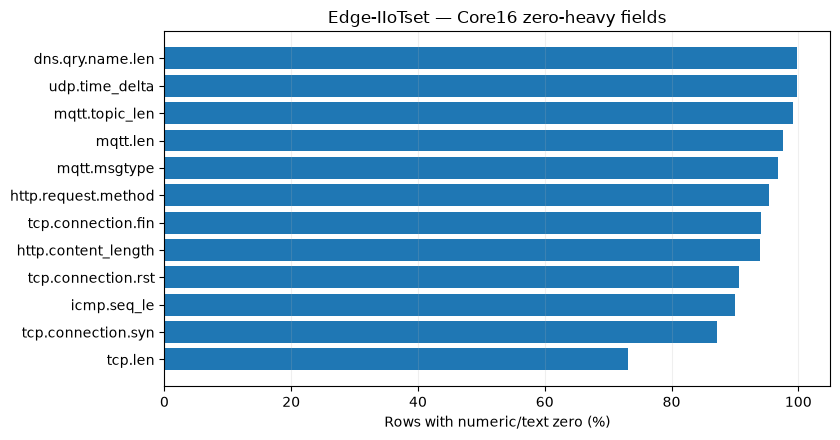

Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\audits\edge_iiotset_v3_feature_quality.json
Saved: D:\J26-CS-336-Network-Flow-V2\network_flow_v2\reports\figures\edge_iiotset_v3_feature_quality.png
Next: 03_data_preparation.ipynb — freeze a group-safe split and export Excel copies.


In [6]:
quality_plot = quality.sort_values('zero_pct').tail(12)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.barh(quality_plot['feature'], quality_plot['zero_pct'])
ax.set_xlim(0, 105)
ax.set_xlabel('Rows with numeric/text zero (%)')
ax.set_title('Edge-IIoTset — Core16 zero-heavy fields')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURE, dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

report = {
    'dataset': 'Edge-IIoTset',
    'source_file': SOURCE.name,
    'source_sha256_from_notebook_01': original_audit['source_sha256'],
    'rows': int(len(selected)),
    'original_columns': len(original_cols),
    'selected_features': FEATURES,
    'categorical_features': CATEGORICAL,
    'numeric_features': NUMERIC,
    'label_columns': LABELS,
    'target': 'Attack_label',
    'export_columns': FIELDS,
    'export_file': OUTPUT.name,
    'binary_label_counts': {'Normal': int(balance['0']), 'Attack':int(balance['1'])},
    'feature_quality': quality.to_dict(orient='records'),
    'pattern_diagnostics': summary,
    'zero_is_missing': False,
    'notes': [
        'No source rows removed, resampled or deduplicated.',
        'Pattern comparisons normalize numeric forms and placeholders; source values are preserved in export.',
        'These packet/protocol features are provisional; not verified as flow features or deployable gateway measurements.',
        'No splitting, model training or testing performed.'
    ]
}
REPORT.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved:', REPORT)
print('Saved:', FIGURE)
print('Next: 03_data_preparation.ipynb — freeze a group-safe split and export Excel copies.')